In [1]:
import os
import glob
import random

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


Size of Training data : 369


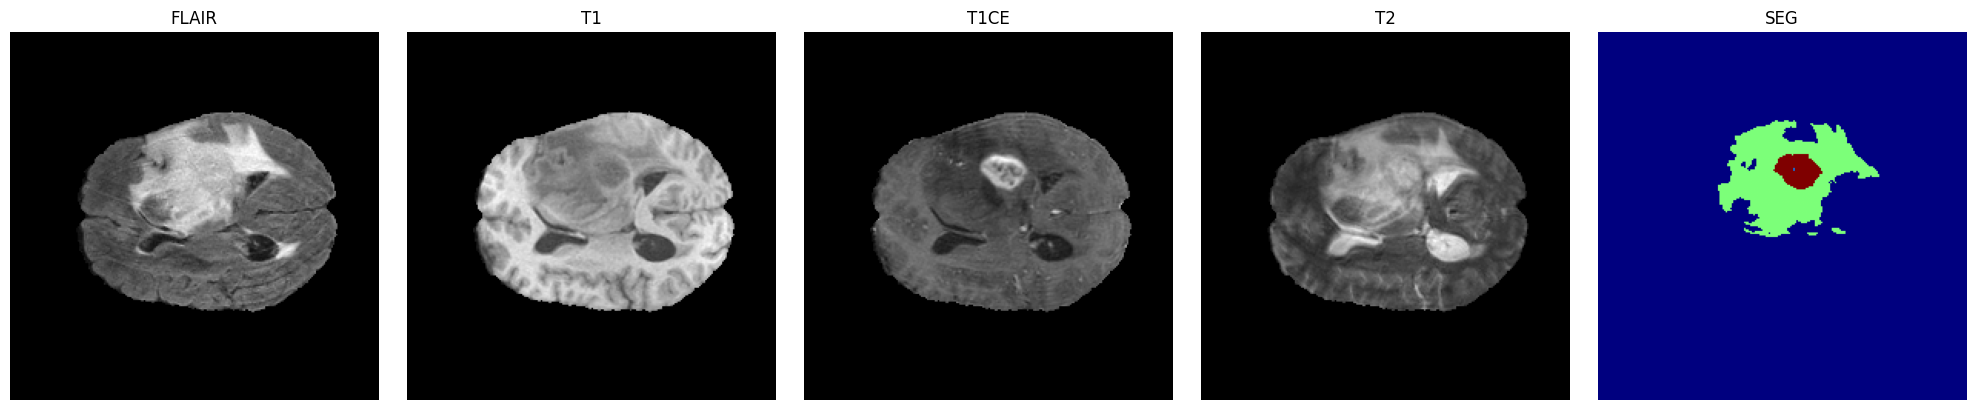

In [2]:
def resolve_data_dir():
    candidates = [
        r"Dataset/BraTS_2020/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData",
        r"../Dataset/BraTS_2020/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData",
    ]
    for candidate in candidates:
        if os.path.isdir(candidate):
            return candidate
    raise FileNotFoundError("Could not locate the BraTS training directory from the current working directory.")


DATA_DIR = resolve_data_dir()
patient_folders = sorted(glob.glob(os.path.join(DATA_DIR, "BraTS20_Training_*")))
print(f"Size of Training data : {len(patient_folders)}")


def find_modality_file(patient_path, modality):
    matches = glob.glob(os.path.join(patient_path, f"*_{modality}.nii*"))
    if not matches:
        raise FileNotFoundError(f"Could not find {modality} file in {patient_path}")
    return matches[0]


def visualize_sample(patient_path):
    patient_id = os.path.basename(patient_path)

    paths = {
        'flair': find_modality_file(patient_path, 'flair'),
        't1': find_modality_file(patient_path, 't1'),
        't1ce': find_modality_file(patient_path, 't1ce'),
        't2': find_modality_file(patient_path, 't2'),
        'seg': find_modality_file(patient_path, 'seg'),
    }

    flair = nib.load(paths['flair']).get_fdata()
    slice_idx = flair.shape[2] // 2

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    for i, (name, path) in enumerate(paths.items()):
        img = nib.load(path).get_fdata()
        if name == 'seg':
            axes[i].imshow(img[:, :, slice_idx], cmap='jet')
        else:
            axes[i].imshow(img[:, :, slice_idx], cmap='gray')
        axes[i].set_title(name.upper())
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


if len(patient_folders) > 0:
    visualize_sample(patient_folders[0])


In [3]:
# SLIDING WINDOW PROTOCOL

def normalize_volume(volume):
    """Normalize a 3D or 4D volume using z-score on non-background voxels."""
    volume = volume.astype(np.float32, copy=True)

    if volume.ndim == 4:
        normalized = np.zeros_like(volume, dtype=np.float32)
        for channel_idx in range(volume.shape[-1]):
            normalized[..., channel_idx] = normalize_volume(volume[..., channel_idx])
        return normalized

    mask = volume > 0
    if np.sum(mask) == 0:
        return volume

    mean = volume[mask].mean()
    std = volume[mask].std()
    volume[mask] = (volume[mask] - mean) / (std + 1e-8)
    return volume


def extract_patches_from_volume(volume, patch_shape, stride_shape):
    """Extract 3D patches from a volume using a sliding window approach."""
    if len(volume.shape) == 3:
        volume = np.expand_dims(volume, axis=-1)

    H, W, D, C = volume.shape
    pH, pW, pD = patch_shape
    sH, sW, sD = stride_shape

    patches = []
    coords = []

    nH = ((H - pH) // sH) + 1
    nW = ((W - pW) // sW) + 1
    nD = ((D - pD) // sD) + 1

    for z in range(nD):
        for y in range(nH):
            for x in range(nW):
                z_start = z * sD
                y_start = y * sH
                x_start = x * sW

                patch = volume[y_start:y_start + pH, x_start:x_start + pW, z_start:z_start + pD, :]
                if patch.shape[:3] != patch_shape:
                    continue

                patches.append(patch)
                coords.append((y_start, x_start, z_start))

    return np.array(patches), coords


def reconstruct_volume_from_patches(patches, coords, original_shape, patch_shape):
    """Reconstruct a full 3D volume from overlapping patches by averaging."""
    H, W, D, C = original_shape
    pH, pW, pD = patch_shape

    reconstructed = np.zeros(original_shape, dtype=np.float32)
    count_map = np.zeros(original_shape[:-1], dtype=np.float32)

    for i, (y, x, z) in enumerate(coords):
        patch = patches[i]
        reconstructed[y:y + pH, x:x + pW, z:z + pD, :] += patch
        count_map[y:y + pH, x:x + pW, z:z + pD] += 1

    count_map = np.expand_dims(count_map, axis=-1)
    reconstructed /= np.maximum(count_map, 1.0)
    return reconstructed


In [4]:
# DATASET FOR PATCH-BASED TRAINING

class BraTSPatchDataset(Dataset):
    def __init__(self, patient_folders, patch_size=(64, 64, 64), patches_per_volume=4, tumor_threshold=100):
        self.patient_folders = list(patient_folders)
        self.patch_size = patch_size
        self.patches_per_volume = patches_per_volume
        self.tumor_threshold = tumor_threshold

    def __len__(self):
        return len(self.patient_folders) * self.patches_per_volume

    def _load_volume(self, patient_path):
        modalities = []
        for modality in ['flair', 't1', 't1ce', 't2']:
            img = nib.load(find_modality_file(patient_path, modality)).get_fdata().astype(np.float32)
            modalities.append(normalize_volume(img))

        volume = np.stack(modalities, axis=-1)
        mask = nib.load(find_modality_file(patient_path, 'seg')).get_fdata().astype(np.float32)
        mask = (mask > 0).astype(np.float32)[..., np.newaxis]
        return volume, mask

    def _sample_patch(self, volume, mask):
        H, W, D, _ = volume.shape
        pH, pW, pD = self.patch_size

        if H < pH or W < pW or D < pD:
            raise ValueError(f"Patch size {self.patch_size} is larger than volume shape {volume.shape}")

        patch_img = None
        patch_mask = None

        for _ in range(10):
            h_start = np.random.randint(0, H - pH + 1)
            w_start = np.random.randint(0, W - pW + 1)
            d_start = np.random.randint(0, D - pD + 1)

            candidate_mask = mask[h_start:h_start + pH, w_start:w_start + pW, d_start:d_start + pD, :]
            if np.sum(candidate_mask) > self.tumor_threshold:
                patch_img = volume[h_start:h_start + pH, w_start:w_start + pW, d_start:d_start + pD, :]
                patch_mask = candidate_mask
                break

        if patch_img is None:
            h_start = np.random.randint(0, H - pH + 1)
            w_start = np.random.randint(0, W - pW + 1)
            d_start = np.random.randint(0, D - pD + 1)
            patch_img = volume[h_start:h_start + pH, w_start:w_start + pW, d_start:d_start + pD, :]
            patch_mask = mask[h_start:h_start + pH, w_start:w_start + pW, d_start:d_start + pD, :]

        return patch_img, patch_mask

    def __getitem__(self, index):
        patient_path = self.patient_folders[index % len(self.patient_folders)]
        volume, mask = self._load_volume(patient_path)
        patch_img, patch_mask = self._sample_patch(volume, mask)

        x = torch.from_numpy(np.transpose(patch_img, (3, 2, 0, 1))).float()
        y = torch.from_numpy(np.transpose(patch_mask, (3, 2, 0, 1))).float()
        return x, y


train_subset = patient_folders[:100] if len(patient_folders) > 100 else patient_folders
train_dataset = BraTSPatchDataset(train_subset, patch_size=(64, 64, 64), patches_per_volume=4)
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print(f"Training subjects: {len(train_subset)}")
print(f"Training batches per epoch: {len(train_loader)}")


Training subjects: 100
Training batches per epoch: 200


In [5]:
# 3D U-NET ARCHITECTURE

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, base_filters=16):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base_filters)
        self.pool1 = nn.MaxPool3d(kernel_size=2, stride=2)
        self.enc2 = DoubleConv(base_filters, base_filters * 2)
        self.pool2 = nn.MaxPool3d(kernel_size=2, stride=2)
        self.bottleneck = DoubleConv(base_filters * 2, base_filters * 4)
        self.up2 = nn.ConvTranspose3d(base_filters * 4, base_filters * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_filters * 4, base_filters * 2)
        self.up1 = nn.ConvTranspose3d(base_filters * 2, base_filters, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_filters * 2, base_filters)
        self.out_conv = nn.Conv3d(base_filters, out_channels, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        p1 = self.pool1(c1)
        c2 = self.enc2(p1)
        p2 = self.pool2(c2)
        bottleneck = self.bottleneck(p2)

        u2 = self.up2(bottleneck)
        u2 = torch.cat([u2, c2], dim=1)
        d2 = self.dec2(u2)

        u1 = self.up1(d2)
        u1 = torch.cat([u1, c1], dim=1)
        d1 = self.dec1(u1)

        return self.out_conv(d1)


model = UNet3D(in_channels=4, out_channels=1, base_filters=16).to(device)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


UNet3D(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (4): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (4): BatchNorm3d(32, eps=1e-05, momentum=0

In [6]:
# TRAINING CONFIGURATION AND MODEL TRAINING

BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 1e-4

# Rebuild loader so the new batch size is applied during training.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


def dice_score_from_logits(logits, targets, threshold=0.5, eps=1e-8):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    targets = (targets >= 0.5).float()
    intersection = (preds * targets).sum(dim=(1, 2, 3, 4))
    denominator = preds.sum(dim=(1, 2, 3, 4)) + targets.sum(dim=(1, 2, 3, 4))
    dice = (2.0 * intersection + eps) / (denominator + eps)
    return dice.mean().item()


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_dice = 0.0

    for batch_x, batch_y in loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_dice += dice_score_from_logits(logits.detach(), batch_y)

    num_batches = max(len(loader), 1)
    return running_loss / num_batches, running_dice / num_batches


for epoch in range(EPOCHS):
    train_loss, train_dice = train_one_epoch(model, train_loader, optimizer, criterion, device)
    print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {train_loss:.4f} - dice: {train_dice:.4f}")


Epoch 1/5 - loss: 0.5718 - dice: 0.3557
Epoch 2/5 - loss: 0.4971 - dice: 0.4834
Epoch 3/5 - loss: 0.4590 - dice: 0.6056
Epoch 4/5 - loss: 0.4276 - dice: 0.6591
Epoch 5/5 - loss: 0.4006 - dice: 0.6572


Running Sliding Window Inference...
Divided volume into 108 patches for inference.


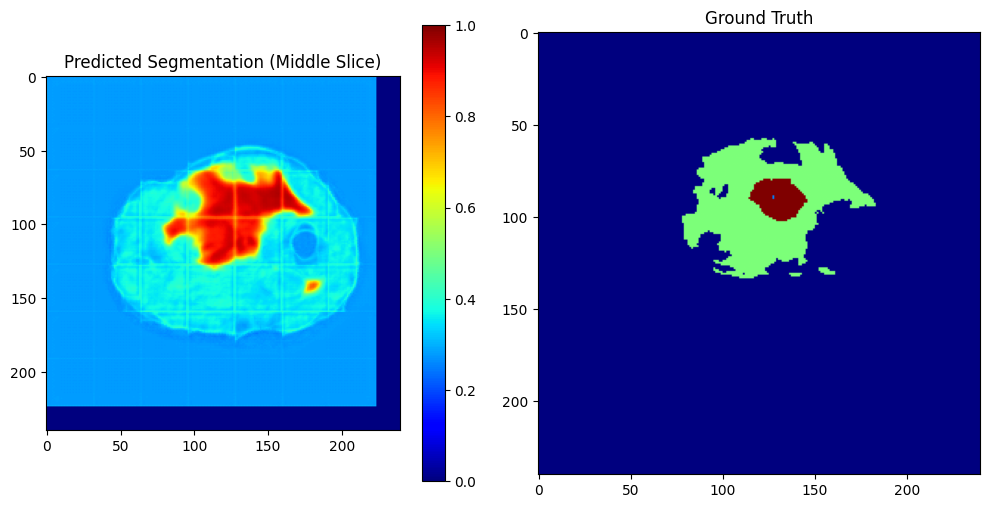

In [7]:
# INFERENCE USING SLIDING WINDOW PROTOCOL


def predict_volume_sliding_window(model, volume, patch_shape=(64, 64, 64), stride=(32, 32, 32), batch_size=4):
    """Predict a 3D volume by running a sliding window over the input."""
    model.eval()
    volume = normalize_volume(volume)
    patches, coords = extract_patches_from_volume(volume, patch_shape, stride)
    print(f"Divided volume into {len(patches)} patches for inference.")

    predictions = []
    with torch.no_grad():
        for start_idx in range(0, len(patches), batch_size):
            patch_batch = patches[start_idx:start_idx + batch_size]
            patch_batch = np.transpose(patch_batch, (0, 4, 3, 1, 2))
            patch_batch = torch.from_numpy(patch_batch).float().to(device)

            logits = model(patch_batch)
            probs = torch.sigmoid(logits).cpu().numpy()
            probs = np.transpose(probs, (0, 3, 4, 2, 1))
            predictions.append(probs)

    predictions = np.concatenate(predictions, axis=0)
    pred_volume = reconstruct_volume_from_patches(
        predictions,
        coords,
        (volume.shape[0], volume.shape[1], volume.shape[2], 1),
        patch_shape,
    )
    return pred_volume


if len(patient_folders) > 0:
    test_patient = patient_folders[0]
    patient_id = os.path.basename(test_patient)

    paths = {
        'flair': find_modality_file(test_patient, 'flair'),
        't1': find_modality_file(test_patient, 't1'),
        't1ce': find_modality_file(test_patient, 't1ce'),
        't2': find_modality_file(test_patient, 't2'),
    }

    modalities = []
    for modality in ['flair', 't1', 't1ce', 't2']:
        img = nib.load(paths[modality]).get_fdata().astype(np.float32)
        modalities.append(img)

    vol_input = np.stack(modalities, axis=-1)

    print("Running Sliding Window Inference...")
    pred_seg = predict_volume_sliding_window(model, vol_input)

    slice_idx = pred_seg.shape[2] // 2
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title("Predicted Segmentation (Middle Slice)")
    plt.imshow(pred_seg[:, :, slice_idx, 0], cmap='jet', vmin=0, vmax=1)
    plt.colorbar()

    seg_path = find_modality_file(test_patient, 'seg')
    if os.path.exists(seg_path):
        gt = nib.load(seg_path).get_fdata()

        plt.subplot(1, 2, 2)
        plt.title("Ground Truth")
        plt.imshow(gt[:, :, slice_idx], cmap='jet')

    plt.tight_layout()
    plt.show()


In [8]:
# METRICS FOR CURRENT MODEL OUTPUT

try:
    from scipy.ndimage import binary_erosion, distance_transform_edt
    _SCIPY_AVAILABLE = True
except Exception:
    _SCIPY_AVAILABLE = False
    print("Warning: scipy is not available. HD95 will be reported as NaN.")


def _safe_div(num, den):
    return float(num) / float(den) if den != 0 else np.nan


def compute_binary_metrics(y_true, y_pred):
    """Compute precision, recall, specificity, and Dice/F1 for binary masks."""
    y_true = y_true.astype(np.uint8).ravel()
    y_pred = y_pred.astype(np.uint8).ravel()

    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = _safe_div(tp, tp + fp)
    recall = _safe_div(tp, tp + fn)
    specificity = _safe_div(tn, tn + fp)
    dice_f1 = _safe_div(2 * tp, 2 * tp + fp + fn)

    if np.isnan(precision) and np.sum(y_pred) == 0 and np.sum(y_true) == 0:
        precision = 1.0
    if np.isnan(recall) and np.sum(y_true) == 0 and np.sum(y_pred) == 0:
        recall = 1.0
    if np.isnan(specificity) and np.sum(y_true) == y_true.size and np.sum(y_pred) == y_pred.size:
        specificity = 1.0
    if np.isnan(dice_f1) and np.sum(y_true) == 0 and np.sum(y_pred) == 0:
        dice_f1 = 1.0

    return {
        "dice_f1": float(dice_f1),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
    }


def _surface_distances(mask_a, mask_b, voxelspacing=(1.0, 1.0, 1.0)):
    """Distances from surface voxels of mask_a to the nearest surface voxel in mask_b."""
    if not _SCIPY_AVAILABLE:
        return np.array([], dtype=np.float32)

    mask_a = mask_a.astype(bool)
    mask_b = mask_b.astype(bool)

    if np.any(mask_a):
        surface_a = mask_a ^ binary_erosion(mask_a)
    else:
        surface_a = mask_a

    if np.any(mask_b):
        surface_b = mask_b ^ binary_erosion(mask_b)
    else:
        surface_b = mask_b

    if not np.any(surface_a):
        return np.array([], dtype=np.float32)

    dt = distance_transform_edt(~surface_b, sampling=voxelspacing)
    return dt[surface_a]


def compute_hd95(y_true, y_pred, voxelspacing=(1.0, 1.0, 1.0)):
    """Compute symmetric HD95 for binary masks."""
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    if not _SCIPY_AVAILABLE:
        return np.nan

    if not np.any(y_true) and not np.any(y_pred):
        return 0.0
    if not np.any(y_true) or not np.any(y_pred):
        return np.inf

    d_true_to_pred = _surface_distances(y_true, y_pred, voxelspacing=voxelspacing)
    d_pred_to_true = _surface_distances(y_pred, y_true, voxelspacing=voxelspacing)
    all_distances = np.concatenate([d_true_to_pred, d_pred_to_true])

    if all_distances.size == 0:
        return np.nan

    return float(np.percentile(all_distances, 95))


if "pred_seg" not in globals():
    raise RuntimeError("pred_seg not found. Please run the inference cell first.")

if "test_patient" not in globals():
    raise RuntimeError("test_patient not found. Please run the inference cell first.")

seg_path = find_modality_file(test_patient, 'seg')
if not os.path.exists(seg_path):
    raise FileNotFoundError(f"Ground truth segmentation file not found: {seg_path}")

gt_img = nib.load(seg_path)
gt = gt_img.get_fdata().astype(np.float32)
voxelspacing = gt_img.header.get_zooms()[:3]

y_true_bin = (gt > 0).astype(np.uint8)
y_pred_bin = (pred_seg[..., 0] >= 0.5).astype(np.uint8)

metrics = compute_binary_metrics(y_true_bin, y_pred_bin)
hd95 = compute_hd95(y_true_bin, y_pred_bin, voxelspacing=voxelspacing)

print("Segmentation Metrics (Current Model Output)")
print(f"Dice          : {metrics['dice_f1']:.4f}")
print(f"Recall        : {metrics['recall']:.4f}")
print(f"Precision     : {metrics['precision']:.4f}")
print(f"Specificity   : {metrics['specificity']:.4f}")
print(f"HD95 (mm)     : {hd95:.4f}" if np.isfinite(hd95) else f"HD95 (mm)     : {hd95}")
print(f"TP/TN/FP/FN   : {metrics['tp']}/{metrics['tn']}/{metrics['fp']}/{metrics['fn']}")


Segmentation Metrics (Current Model Output)
Dice          : 0.8617
Recall        : 0.7853
Precision     : 0.9546
Specificity   : 0.9991
HD95 (mm)     : 8.7178
TP/TN/FP/FN   : 166462/8708111/7910/45517


In [11]:
# VALIDATION METRICS SETUP

import pandas as pd


def resolve_validation_dir():
    candidates = [
        r"Dataset/BraTS_2020/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData",
        r"../Dataset/BraTS_2020/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData",
    ]
    for candidate in candidates:
        if os.path.isdir(candidate):
            return candidate
    raise FileNotFoundError("Could not locate the BraTS validation directory from the current working directory.")


def get_validation_folders(validation_dir):
    folders = sorted(glob.glob(os.path.join(validation_dir, "*")))
    return [f for f in folders if os.path.isdir(f)]


def evaluate_on_validation_set(model, validation_folders, patch_shape=(64, 64, 64), stride=(32, 32, 32), max_cases=None):
    records = []

    if max_cases is not None:
        validation_folders = validation_folders[:max_cases]

    for i, patient_path in enumerate(validation_folders, start=1):
        patient_id = os.path.basename(patient_path)

        try:
            flair_path = find_modality_file(patient_path, 'flair')
            t1_path = find_modality_file(patient_path, 't1')
            t1ce_path = find_modality_file(patient_path, 't1ce')
            t2_path = find_modality_file(patient_path, 't2')
        except Exception as e:
            records.append({
                "patient": patient_id,
                "status": f"missing modality: {e}",
            })
            continue

        seg_candidates = glob.glob(os.path.join(patient_path, "*_seg.nii*"))
        if len(seg_candidates) == 0:
            records.append({
                "patient": patient_id,
                "status": "no ground-truth segmentation",
            })
            continue

        seg_path = seg_candidates[0]

        mods = []
        for p in [flair_path, t1_path, t1ce_path, t2_path]:
            mods.append(nib.load(p).get_fdata().astype(np.float32))
        vol_input = np.stack(mods, axis=-1)

        pred_seg = predict_volume_sliding_window(
            model,
            vol_input,
            patch_shape=patch_shape,
            stride=stride,
            batch_size=4,
        )

        gt_img = nib.load(seg_path)
        gt = gt_img.get_fdata().astype(np.float32)
        voxelspacing = gt_img.header.get_zooms()[:3]

        y_true_bin = (gt > 0).astype(np.uint8)
        y_pred_bin = (pred_seg[..., 0] >= 0.5).astype(np.uint8)

        m = compute_binary_metrics(y_true_bin, y_pred_bin)
        hd95 = compute_hd95(y_true_bin, y_pred_bin, voxelspacing=voxelspacing)

        records.append({
            "patient": patient_id,
            "status": "ok",
            "dice": m["dice_f1"],
            "recall": m["recall"],
            "precision": m["precision"],
            "specificity": m["specificity"],
            "hd95_mm": hd95,
        })

        print(f"[{i}/{len(validation_folders)}] {patient_id} done")

    return pd.DataFrame(records)


VAL_DIR = resolve_validation_dir()
validation_folders = get_validation_folders(VAL_DIR)
print(f"Validation subjects found: {len(validation_folders)}")


Validation subjects found: 125


In [10]:
# RUN VALIDATION METRICS

# Set to None to evaluate all validation subjects.
MAX_VAL_CASES = 5

val_results = evaluate_on_validation_set(
    model,
    validation_folders,
    patch_shape=(64, 64, 64),
    stride=(32, 32, 32),
    max_cases=MAX_VAL_CASES,
)

if len(val_results) == 0:
    print("No validation records were produced.")
else:
    display(val_results.head(20))

    ok = val_results[val_results["status"] == "ok"].copy()
    print(f"Processed: {len(val_results)} | With GT: {len(ok)}")

    if len(ok) > 0:
        summary = ok[["dice", "recall", "precision", "specificity", "hd95_mm"]].mean(numeric_only=True)
        print("\nValidation mean metrics")
        for k, v in summary.items():
            if k == "hd95_mm" and not np.isfinite(v):
                print(f"{k}: {v}")
            else:
                print(f"{k}: {float(v):.4f}")
    else:
        print("No validation subjects with ground-truth segmentation were found.")


,patient,status
0,BraTS20_Validation_001,no ground-truth segmentation
1,BraTS20_Validation_002,no ground-truth segmentation
2,BraTS20_Validation_003,no ground-truth segmentation
3,BraTS20_Validation_004,no ground-truth segmentation
4,BraTS20_Validation_005,no ground-truth segmentation


Processed: 5 | With GT: 0
No validation subjects with ground-truth segmentation were found.


Divided volume into 108 patches for inference.


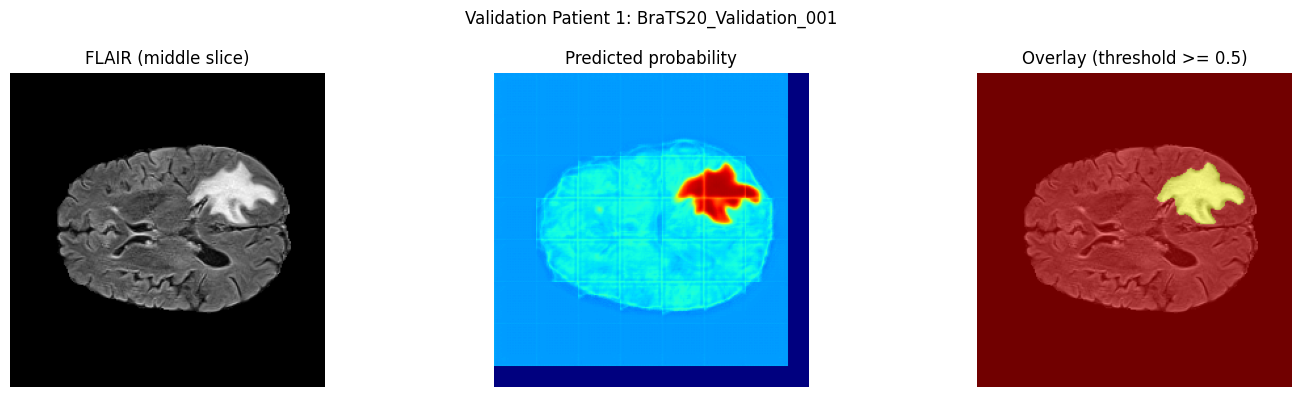

Divided volume into 108 patches for inference.


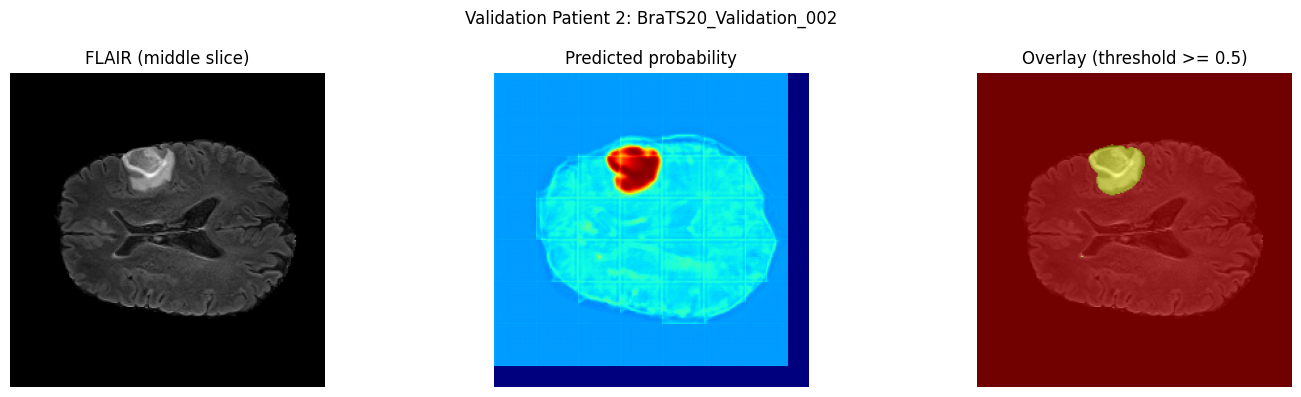

Divided volume into 108 patches for inference.


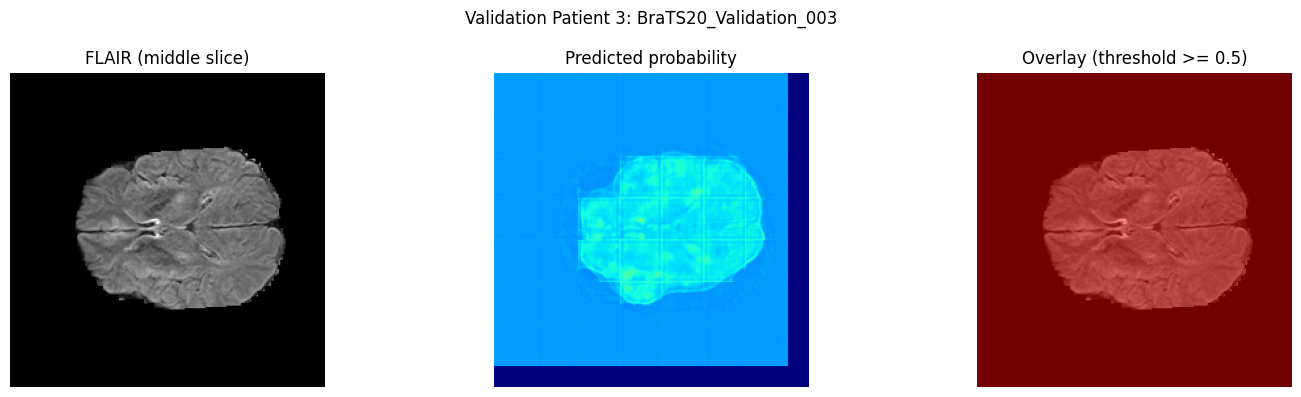

Divided volume into 108 patches for inference.


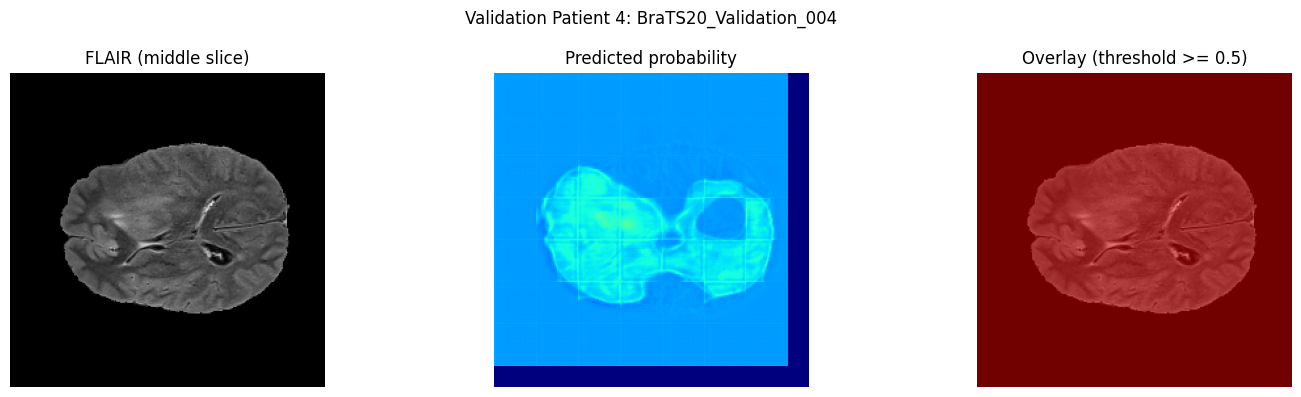

Divided volume into 108 patches for inference.


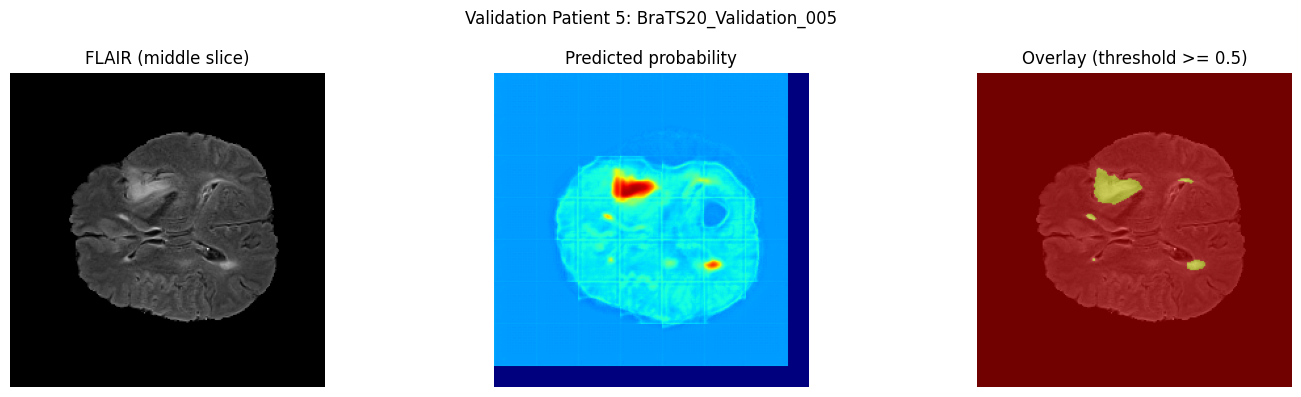

Divided volume into 108 patches for inference.


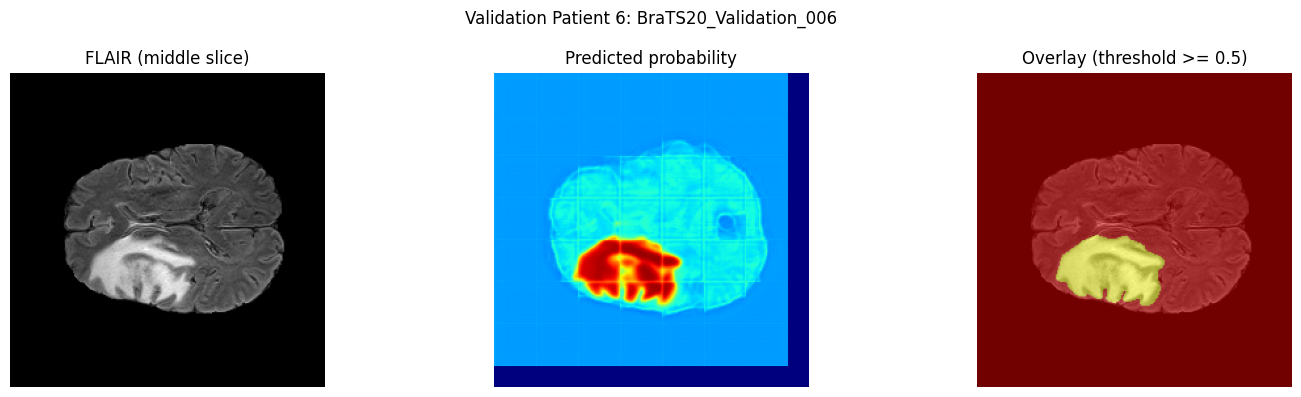

Divided volume into 108 patches for inference.


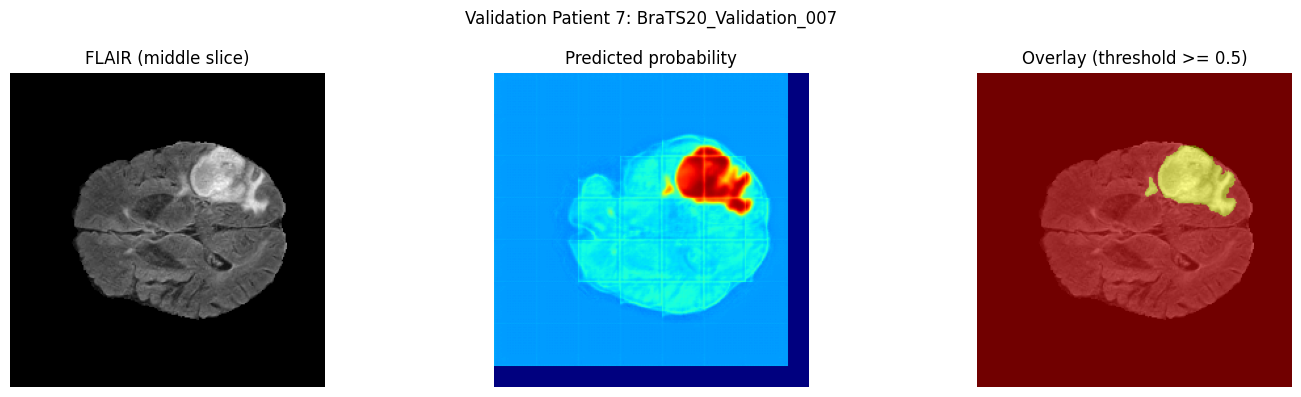

Divided volume into 108 patches for inference.


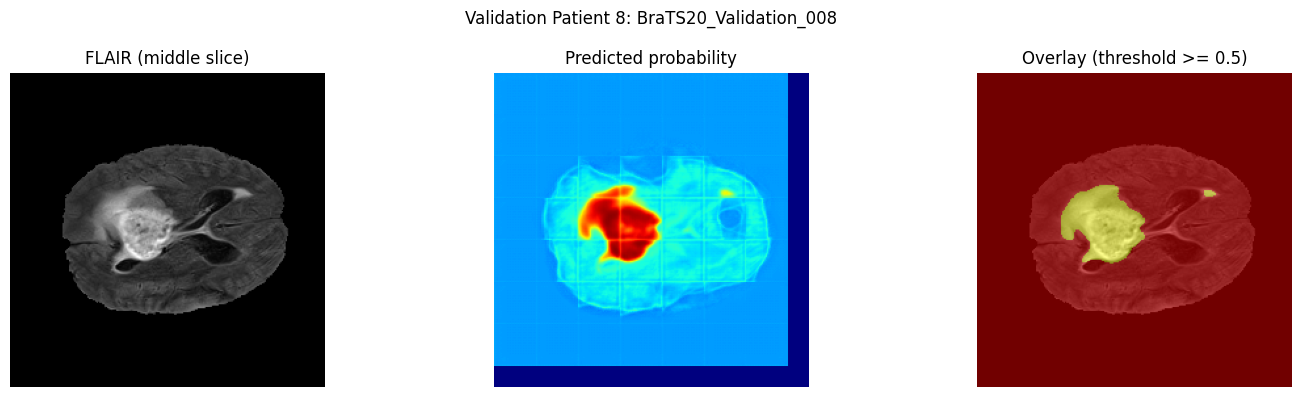

Divided volume into 108 patches for inference.


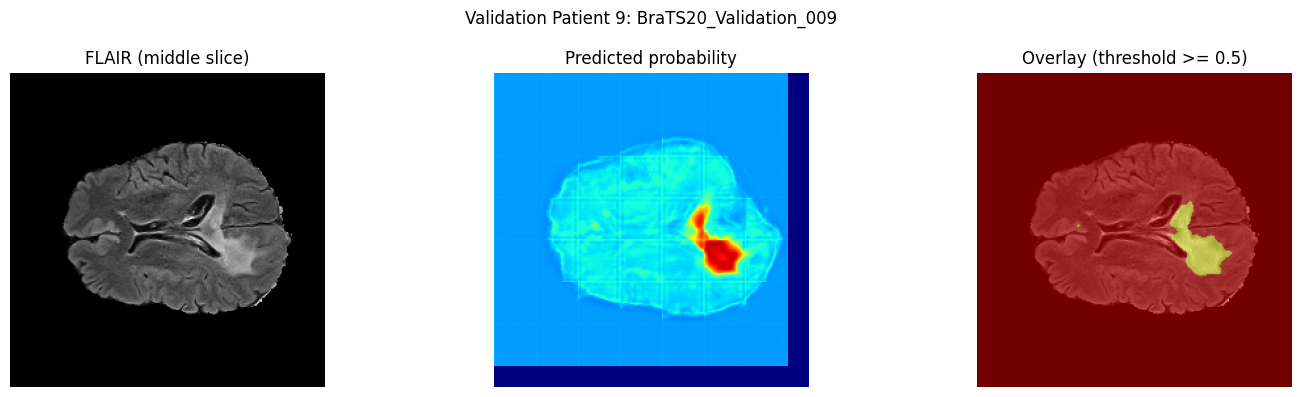

Divided volume into 108 patches for inference.


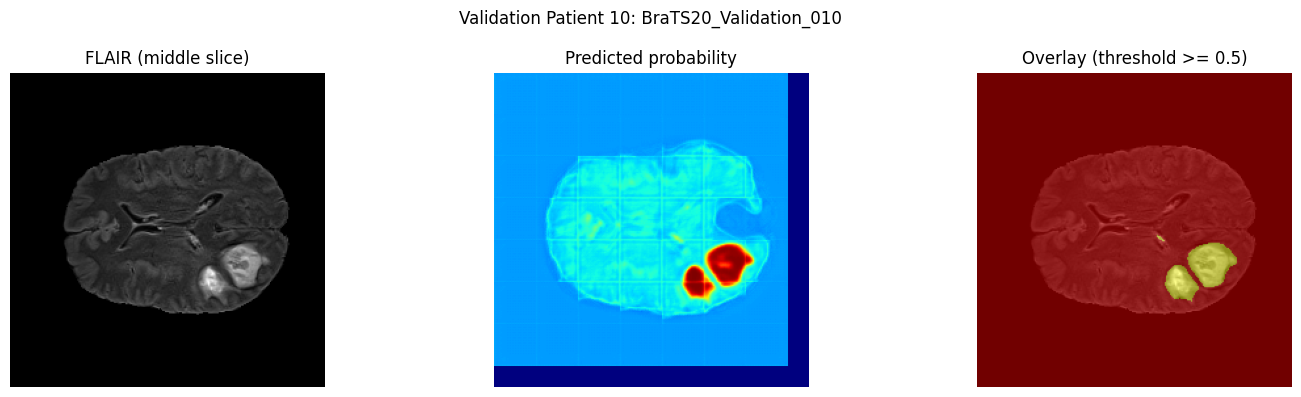

In [12]:
# DISPLAY PREDICTIONS FOR FIRST 10 VALIDATION PATIENTS (NO GROUND TRUTH)

if "validation_folders" not in globals() or len(validation_folders) == 0:
    raise RuntimeError("validation_folders not found. Run Cell 9 first.")

if "model" not in globals():
    raise RuntimeError("model not found. Run model/training cells first.")

num_cases_to_show = min(10, len(validation_folders))

for idx, patient_path in enumerate(validation_folders[:num_cases_to_show], start=1):
    patient_id = os.path.basename(patient_path)

    flair_path = find_modality_file(patient_path, 'flair')
    t1_path = find_modality_file(patient_path, 't1')
    t1ce_path = find_modality_file(patient_path, 't1ce')
    t2_path = find_modality_file(patient_path, 't2')

    flair = nib.load(flair_path).get_fdata().astype(np.float32)
    t1 = nib.load(t1_path).get_fdata().astype(np.float32)
    t1ce = nib.load(t1ce_path).get_fdata().astype(np.float32)
    t2 = nib.load(t2_path).get_fdata().astype(np.float32)

    vol_input = np.stack([flair, t1, t1ce, t2], axis=-1)
    pred_seg = predict_volume_sliding_window(
        model,
        vol_input,
        patch_shape=(64, 64, 64),
        stride=(32, 32, 32),
        batch_size=4,
    )

    slice_idx = pred_seg.shape[2] // 2
    pred_slice = pred_seg[:, :, slice_idx, 0]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"Validation Patient {idx}: {patient_id}", fontsize=12)

    axes[0].imshow(flair[:, :, slice_idx], cmap='gray')
    axes[0].set_title("FLAIR (middle slice)")
    axes[0].axis('off')

    axes[1].imshow(pred_slice, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title("Predicted probability")
    axes[1].axis('off')

    axes[2].imshow(flair[:, :, slice_idx], cmap='gray')
    axes[2].imshow(pred_slice >= 0.5, cmap='autumn', alpha=0.45)
    axes[2].set_title("Overlay (threshold >= 0.5)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
